# From logic gates to associative memory

Before neural networks were trained with gradients, they were built from two older ideas: a
neuron as a **threshold unit** that computes logic, and a synapse that strengthens when its two
neurons are active together (**Hebbian learning**). This notebook builds both from scratch and
ends with a Hopfield network, a recurrent network that stores memories as stable states and
recalls them from fragments.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})
rng = np.random.default_rng(0)

## McCulloch-Pitts neurons compute logic

McCulloch and Pitts (1943) modelled a neuron as a unit that outputs 1 if the weighted sum of
its binary inputs reaches a threshold $\theta$:

$$y = \mathbb 1\Big[\textstyle\sum_j w_j x_j \ge \theta\Big].$$

With the right weights and threshold a single unit implements AND, OR, or NOT, and networks of
such units can implement any Boolean function.

In [2]:
def mp_neuron(x, w, theta):
    return (np.asarray(x) @ np.asarray(w) >= theta).astype(int)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
print("x1 x2 | AND OR")
for x, a, o in zip(X, mp_neuron(X, [1, 1], 1.5), mp_neuron(X, [1, 1], 0.5)):
    print(f" {x[0]}  {x[1]} |  {a}   {o}")
print("NOT:", mp_neuron([[0], [1]], [-1], -0.5))

x1 x2 | AND OR
 0  0 |  0   0
 0  1 |  0   1
 1  0 |  0   1
 1  1 |  1   1
NOT: [1 0]


## A unit is a hyperplane

Writing the threshold as a bias, $y = \mathbb 1[\mathbf w\cdot\mathbf x + b \ge 0]$, shows the
geometry. The unit splits input space with the line (in general, the hyperplane)
$\mathbf w\cdot\mathbf x + b = 0$. The dot product $\mathbf w\cdot\mathbf x =
\lVert\mathbf w\rVert\lVert\mathbf x\rVert\cos\theta$ measures how well the input aligns with the
weight vector, so a unit is a **template matcher**.

AND and OR are *linearly separable*: one line puts the 1s on one side. XOR (output 1 if exactly
one input is on) is not. No line can separate it.

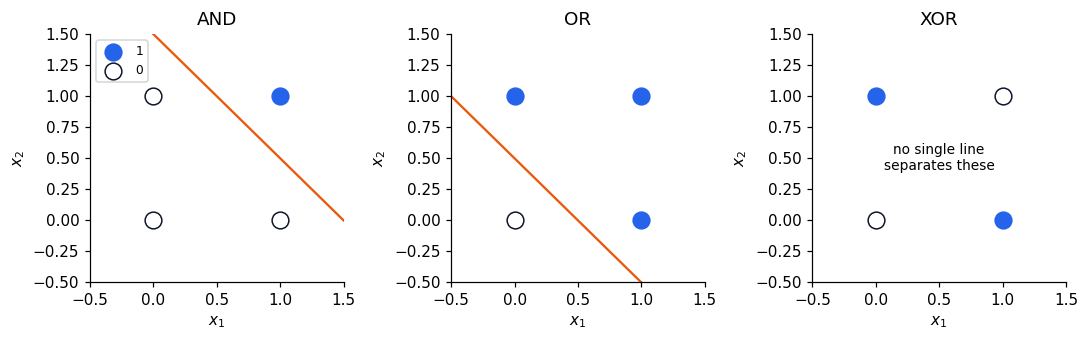

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
targets = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}
lines = {"AND": ([1, 1], -1.5), "OR": ([1, 1], -0.5)}
xs = np.linspace(-0.5, 1.5, 2)
for ax, (name, t) in zip(axes, targets.items()):
    t = np.array(t)
    ax.scatter(*X[t == 1].T, s=120, color="#2563eb", label="1", zorder=3)
    ax.scatter(*X[t == 0].T, s=120, facecolor="white", edgecolor="#0f172a", label="0", zorder=3)
    if name in lines:
        (w1, w2), b = lines[name]
        ax.plot(xs, -(w1 * xs + b) / w2, color="#ea580c")
    else:
        ax.text(0.5, 0.5, "no single line\nseparates these", ha="center", va="center", fontsize=9)
    ax.set(title=name, xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="$x_1$", ylabel="$x_2$")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## The perceptron learning rule

Rosenblatt's perceptron (1958) *learns* the weights. Present an example, compare the output $y$
with the target $t$, and nudge the weights only when it is wrong:

$$\mathbf w \leftarrow \mathbf w + \eta\,(t - y)\,\mathbf x, \qquad b \leftarrow b + \eta\,(t - y).$$

If the classes are linearly separable, this is guaranteed to converge (the perceptron
convergence theorem). We train it on two clouds of points.

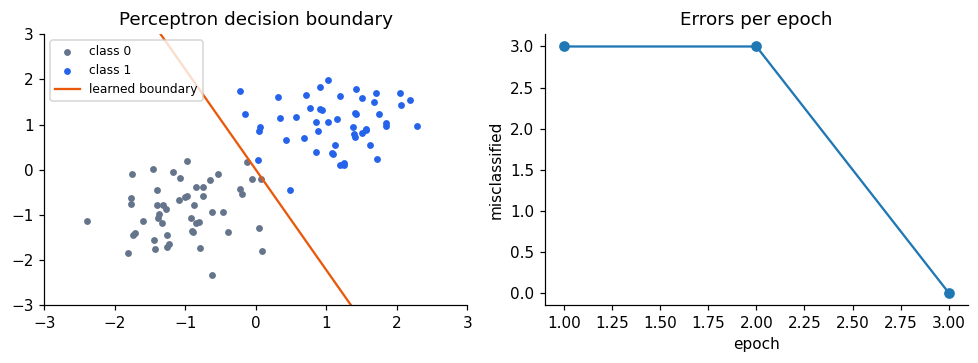

In [4]:
def train_perceptron(X, t, eta=0.1, epochs=50):
    w, b, errors = np.zeros(X.shape[1]), 0.0, []
    for _ in range(epochs):
        n_err = 0
        for i in rng.permutation(len(X)):
            y = int(X[i] @ w + b >= 0)
            w += eta * (t[i] - y) * X[i]
            b += eta * (t[i] - y)
            n_err += int(y != t[i])
        errors.append(n_err)
        if n_err == 0:
            break
    return w, b, errors

Xc = np.vstack([rng.normal([-1, -1], 0.6, (50, 2)), rng.normal([1.2, 1], 0.6, (50, 2))])
tc = np.repeat([0, 1], 50)
w, b, errors = train_perceptron(Xc, tc)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].scatter(*Xc[tc == 0].T, s=12, color="#64748b", label="class 0")
axes[0].scatter(*Xc[tc == 1].T, s=12, color="#2563eb", label="class 1")
xx = np.linspace(-3, 3, 2)
axes[0].plot(xx, -(w[0] * xx + b) / w[1], color="#ea580c", label="learned boundary")
axes[0].set(xlim=(-3, 3), ylim=(-3, 3), title="Perceptron decision boundary")
axes[0].legend(fontsize=8)
axes[1].plot(range(1, len(errors) + 1), errors, marker="o")
axes[1].set(xlabel="epoch", ylabel="misclassified", title="Errors per epoch")
plt.tight_layout()
plt.show()

On XOR, the same rule never settles: every line it tries misclassifies at least one point.
This is what Minsky and Papert (1969) made famous.

In [5]:
_, _, errors_xor = train_perceptron(X.astype(float), np.array([0, 1, 1, 0]), epochs=30)
print("XOR errors per epoch:", errors_xor)

XOR errors per epoch: [4, 4, 2, 2, 3, 4, 3, 2, 2, 3, 4, 3, 3, 2, 2, 3, 1, 3, 3, 3, 1, 2, 2, 2, 4, 4, 2, 4, 2, 3]


## A hidden layer solves XOR

XOR is "OR but not AND". Two hidden threshold units compute OR and AND, and an output unit
combines them. The hidden layer remaps the inputs into a space where the problem *is* linearly
separable, which is the central idea of every deep network. What a single-layer rule cannot do
is *learn* such hidden weights; that needs backpropagation (notebook 6).

In [6]:
def xor_net(x):
    h_or = mp_neuron(x, [1, 1], 0.5)
    h_and = mp_neuron(x, [1, 1], 1.5)
    return mp_neuron(np.column_stack([h_or, h_and]), [1, -1], 0.5)

print("XOR:", xor_net(X))

XOR: [0 1 1 0]


## Hebbian learning and the linear associator

*Cells that fire together wire together.* Hebb's rule changes a weight in proportion to the
product of pre- and postsynaptic activity: $\Delta w_{ij} = \eta\, f_i\, s_j$. Summed over
pattern pairs $(\mathbf s^k, \mathbf f^k)$ it builds a weight matrix from outer products,

$$W = \sum_k \mathbf f^k (\mathbf s^k)^\top ,$$

so that presenting $\mathbf s^k$ recalls $\mathbf f^k$. This is a **linear associator**, a model
of how one stimulus (a rose) can evoke another (its smell). With bipolar patterns ($\pm 1$),
recall is $\operatorname{sign}(W\mathbf s)$.

In [7]:
S = np.array([[1, -1, -1, -1], [-1, 1, -1, -1], [-1, -1, 1, -1], [-1, -1, -1, 1]])
F = np.array([[1, -1, -1], [1, -1, 1], [-1, 1, -1], [-1, 1, 1]])
W = sum(np.outer(f, s) for s, f in zip(S, F))
print("W =\n", W)
print("recall all four:", np.array_equal(np.sign(S @ W.T), F))

noisy = np.array([1, -1, 1, -1])   # s1 with the third element flipped
print("noisy s1 ->", np.sign(W @ noisy), " (f1 =", F[0], ")")

W =
 [[ 2  2 -2 -2]
 [-2 -2  2  2]
 [-2  2 -2  2]]
recall all four: True
noisy s1 -> [ 0  0 -1]  (f1 = [ 1 -1 -1] )


Recall works because the four input patterns are nearly orthogonal. The noisy input, halfway
between $\mathbf s^1$ and $\mathbf s^3$, produces a blend with zeros in it, where the evidence
is tied. Associative memory degrades gracefully rather than failing outright.

## Hopfield networks: memories as attractors

Hopfield (1982) made the associator **recurrent** and **auto**-associative: $N$ binary neurons
($\pm1$), each connected to every other with symmetric weights, stored with the Hebb rule

$$W = \frac1N \sum_k \boldsymbol\xi^k (\boldsymbol\xi^k)^\top, \qquad w_{ii} = 0.$$

Neurons update one at a time, $x_i \leftarrow \operatorname{sign}(\sum_j w_{ij} x_j)$. Symmetric
weights guarantee that each update never increases the energy

$$E = -\tfrac12\, \mathbf x^\top W \mathbf x ,$$

so the network rolls downhill until it reaches a stable state. The stored patterns are minima
of $E$, and a corrupted cue falls into the nearest one: **pattern completion**.

We store four 10×10 glyphs.

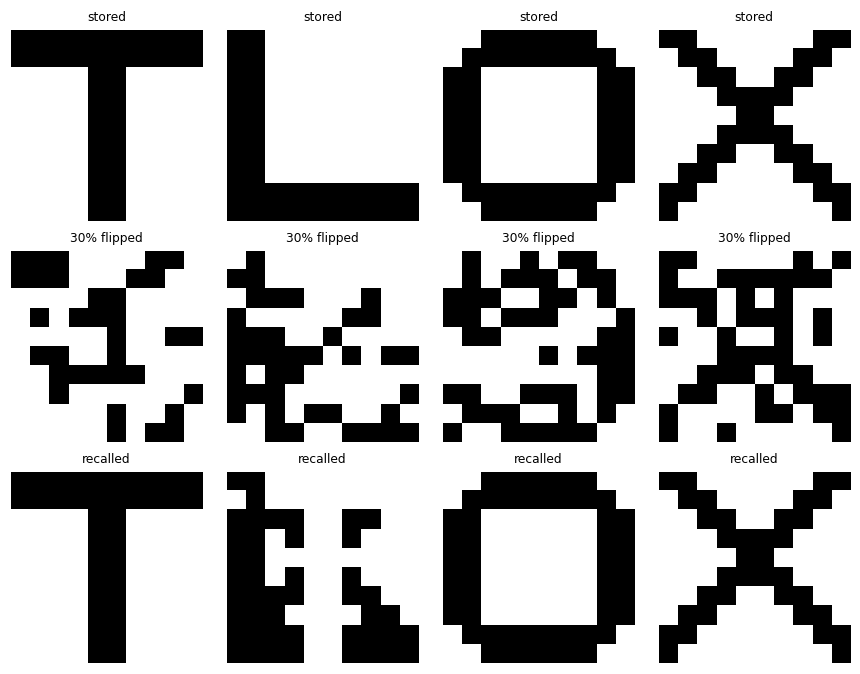

In [8]:
glyphs = {
    "T": ["##########", "##########", "....##....", "....##....", "....##....",
          "....##....", "....##....", "....##....", "....##....", "....##...."],
    "L": ["##........", "##........", "##........", "##........", "##........",
          "##........", "##........", "##........", "##########", "##########"],
    "O": ["..######..", ".########.", "##......##", "##......##", "##......##",
          "##......##", "##......##", "##......##", ".########.", "..######.."],
    "X": ["##......##", ".##....##.", "..##..##..", "...####...", "....##....",
          "...####...", "..##..##..", ".##....##.", "##......##", "#........#"],
}
patterns = np.array([[1 if c == "#" else -1 for row in g for c in row] for g in glyphs.values()])
N = patterns.shape[1]

class Hopfield:
    def __init__(self, patterns):
        self.W = patterns.T @ patterns / patterns.shape[1]
        np.fill_diagonal(self.W, 0)

    def energy(self, x):
        return -0.5 * x @ self.W @ x

    def recall(self, x, sweeps=5, rng=rng):
        x, energies = x.copy(), [self.energy(x)]
        for _ in range(sweeps):
            for i in rng.permutation(len(x)):
                x[i] = 1 if self.W[i] @ x >= 0 else -1
            energies.append(self.energy(x))
        return x, energies

net = Hopfield(patterns)

def corrupt(x, frac, rng=rng):
    x = x.copy()
    idx = rng.choice(len(x), int(frac * len(x)), replace=False)
    x[idx] *= -1
    return x

fig, axes = plt.subplots(3, 4, figsize=(8, 6.2))
for j, p in enumerate(patterns):
    cue = corrupt(p, 0.3)
    out, en = net.recall(cue)
    for i, (img, title) in enumerate([(p, "stored"), (cue, "30% flipped"), (out, "recalled")]):
        axes[i, j].imshow(img.reshape(10, 10), cmap="Greys", vmin=-1, vmax=1)
        axes[i, j].set_title(title, fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

With 30% of pixels flipped, T, O and X roll back into their memories. The L does not: it settles
into a **spurious attractor**, a stable state that was never stored and that resembles a
mixture of the L and other glyphs. Spurious states arise because the glyphs are correlated (they
share many background pixels), so their energy basins overlap. Real memories have the same
weakness, which is one reason the brain is thought to decorrelate (pattern-separate) inputs
before storing them.

Whatever the outcome, the energy drops in the first sweep and then stays flat: the state has
reached a minimum.

In [9]:
_, en = net.recall(corrupt(patterns[0], 0.3), sweeps=4)
print("energy per sweep:", np.round(en, 2))

energy per sweep: [ -8.4  -49.52 -49.52 -49.52 -49.52]


## Capacity

Each stored pattern adds interference, the *crosstalk* from all other patterns, to every
neuron's input. For random patterns, recall breaks down once the number of patterns exceeds
about $0.14N$. We can measure this directly with $N = 100$.

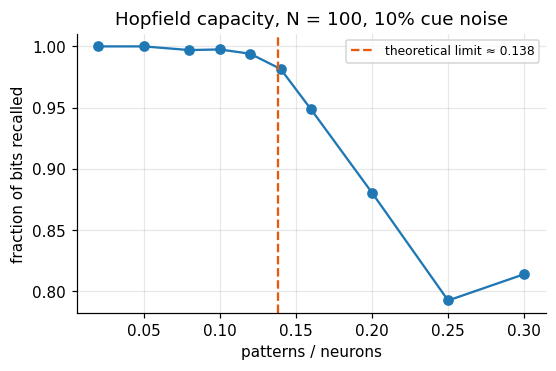

In [10]:
def recall_quality(n_patterns, N=100, trials=20, noise=0.1):
    scores = []
    for _ in range(trials):
        P = rng.choice([-1, 1], size=(n_patterns, N))
        hop = Hopfield(P)
        k = rng.integers(n_patterns)
        out, _ = hop.recall(corrupt(P[k], noise), sweeps=5)
        scores.append(np.mean(out == P[k]))
    return np.mean(scores)

ks = [2, 5, 8, 10, 12, 14, 16, 20, 25, 30]
quality = [recall_quality(k) for k in ks]
fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.plot(np.array(ks) / 100, quality, marker="o")
ax.axvline(0.138, color="#ea580c", ls="--", label="theoretical limit ≈ 0.138")
ax.set(xlabel="patterns / neurons", ylabel="fraction of bits recalled",
       title="Hopfield capacity, N = 100, 10% cue noise")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

Recall is near perfect for a handful of patterns and collapses past the limit. The glyphs above
are far from random (they share many pixels), which is why even four of them already produce a
spurious state in 100 neurons. Modern variants raise the capacity with sharper energy functions; the
attention mechanism in transformers turns out to be one such modern Hopfield update.

## Summary

- A threshold unit is a hyperplane; it computes any linearly separable function.
- The perceptron rule learns such a hyperplane, but cannot learn XOR.
- A hidden layer makes XOR separable, but learning hidden weights needs backpropagation.
- Hebbian outer products build associative memories that tolerate noise.
- A Hopfield network stores patterns as energy minima and completes corrupted cues, up to about
  $0.14N$ random patterns.